In [2]:
import numpy as np
import spectral.io.envi as envi
import matplotlib.pyplot as plt
import pandas as pd
import os

In [3]:

input_path = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/351_1_240506-160920/capture/351_1_240506-160920.hdr'
output_dir = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing'
output_path = os.path.join(output_dir, 'espectros_swir_351_1.csv')


In [4]:
img_spectral = envi.open(input_path)


/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/.venv/lib/python3.11/site-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


In [5]:
img_array = img_spectral.load()
print(f"Formato do array: {img_array.shape}")

Formato do array: (289, 320, 256)


In [6]:
img_array = np.array(img_array)

In [7]:
altura, largura, n_bandas = img_array.shape
n_amostras = altura * largura
espectros_matriz = img_array.reshape(n_amostras, n_bandas)
media_total = espectros_matriz.mean()
media_espectro = espectros_matriz.mean(axis=0)


In [8]:
print(f"Formato do array: {img_array.shape}")
print(f"Matriz final: {espectros_matriz.shape}")
print(f"n_amostras (pixels): {n_amostras}")
print(f"n_bandas espectrais: {n_bandas}")
print(f"Faixa de valores: [{espectros_matriz.min():.2f}, {espectros_matriz.max():.2f}]")
print(f"Média total da imagem HSI: {media_total:.2f}")


Formato do array: (289, 320, 256)
Matriz final: (92480, 256)
n_amostras (pixels): 92480
n_bandas espectrais: 256
Faixa de valores: [0.00, 16091.00]
Média total da imagem HSI: 3566.57


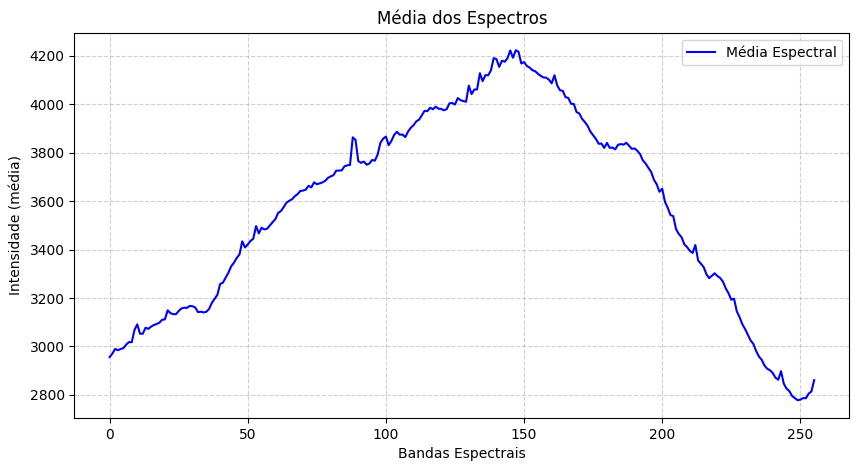

In [10]:
# Plotar média espectral
plt.figure(figsize=(10, 5))
plt.plot(range(n_bandas), media_espectro, label="Média Espectral", color='blue')
plt.xlabel("Bandas Espectrais")
plt.ylabel("Intensidade (média)")
plt.title("Média dos Espectros")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()
